# 05 — Single-line galaxies against observed wavelength

A galaxy with only one detectable line has to be identified from the wavelength and flux of that line alone,
so what matters for line confusion is the mix of lines that produce single-line detections at a given observed
wavelength λ_obs = λ_rest (1 + z) and flux. This notebook looks at the **single-line galaxies** of the mock inside
the grism bandpass (10 000–19 300 Å): galaxies with exactly one in-band line above the primary threshold
1.5×10⁻¹⁶ erg s⁻¹ cm⁻² and no other in-band line above 6×10⁻¹⁷. It shows the quantiles of the flux of the single
line as a function of λ_obs, and the share of each line among the single-line galaxies brighter than a flux
threshold in twelve slices of the bandpass. Lines that are the single line of fewer than 1 % of the single-line
galaxies in every slice are counted in the scan but left out of the plots.

The lines are the seven that matter for the catalog ([O III] λ4363 and [S III] λ6312 are too faint to be
detected and are ignored, also as second lines). The fluxes come from the base catalog, which is complete above
10⁻¹⁷ and therefore contains every line above 6×10⁻¹⁷ of every galaxy with a line above 1.5×10⁻¹⁶. It is read
slice by slice (`base.read_slices`, a few hundred MB), and the single line of each single-line galaxy is
histogrammed in λ_obs (bins of 25 Å) and log₁₀ F (bins of 0.02 dex); the plots are made from that histogram.
The redshift is `redshift_rsd`, the one the pipeline uses for the bandpass test. Reading the 222 M galaxies
of the base catalog takes a few minutes on a login node.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # diffsky imports JAX; keep it off the GPU

import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from romanmock import BaseCatalog, plotting
from romanmock.roman import GRISM_WAVE_RANGE_ANGSTROM as WAVE_RANGE

plotting.use_style()

MOCK = "sdss_feniks_hizels_260710_09_07_2026"                          # version of the diffsky mock
ROOT = f"/global/cfs/cdirs/m4943/Simulations/RomanMocks/{MOCK}"        # products of romanmock for this mock
base = BaseCatalog(f"{ROOT}/base")

F_PRIMARY, F_SECOND = 1.5e-16, 6.0e-17                                 # erg/s/cm^2: the single line, and the limit for a second line
LINES = ["Ha", "OIII_5007", "SIII_9532", "SIII_9069", "Hb", "OIII_4959", "OII_3727"]     # brightest to faintest in the mock
LABEL = {"Ha": "Hα", "Hb": "Hβ", "OIII_5007": "[O III] λ5007", "OIII_4959": "[O III] λ4959", "OII_3727": "[O II] λ3727",
         "SIII_9532": "[S III] λ9532", "SIII_9069": "[S III] λ9069"}
rest = np.array([base.line_set.rest_waves[base.line_set.bit(line)] for line in LINES])
sci = lambda x: rf"${float(f'{x:.1e}'.split('e')[0]):g}\times10^{{{int(f'{x:.1e}'.split('e')[1])}}}$"

wave_edges = np.arange(WAVE_RANGE[0], WAVE_RANGE[1] + 1e-6, 25.0)       # observed wavelength [A]
logf_edges = np.round(np.arange(-16.0, -11.0 + 1e-9, 0.02), 6)         # log10 flux of the single line
wave_c = 0.5 * (wave_edges[1:] + wave_edges[:-1])
hist = np.zeros((len(LINES), wave_edges.size - 1, logf_edges.size - 1), dtype=np.int64)   # (line, wavelength bin, flux bin)

t0, n_read, n_single = time.time(), 0, 0
for data in base.read_slices(["redshift_rsd", *[f"{line}_flux" for line in LINES]]):     # one slice at a time
    z = np.asarray(data["redshift_rsd"], dtype=np.float64)
    flux = np.stack([np.asarray(data[f"{line}_flux"], dtype=np.float64) for line in LINES], axis=1)
    wave = rest[None, :] * (1 + z[:, None])
    in_band = (wave >= WAVE_RANGE[0]) & (wave < WAVE_RANGE[1])
    single = (np.sum(in_band & (flux > F_PRIMARY), axis=1) == 1) & (np.sum(in_band & (flux > F_SECOND), axis=1) == 1)
    n_read, n_single = n_read + z.size, n_single + int(single.sum())
    for i in range(len(LINES)):
        m = single & in_band[:, i] & (flux[:, i] > F_PRIMARY)                                 # line i is the single line
        hist[i] += np.histogram2d(wave[m, i], np.log10(flux[m, i]), bins=(wave_edges, logf_edges))[0].astype(np.int64)
print(f"{n_read:,} base galaxies read in {time.time() - t0:.0f} s; {n_single:,} single-line galaxies "
      f"(one in-band line > {F_PRIMARY:.1e}, no other > {F_SECOND:.1e})")

N_PANELS, MIN_SHARE = 12, 0.01                                          # slices of the bandpass; a line is kept if it is the single line of
edges = np.linspace(WAVE_RANGE[0], WAVE_RANGE[1], N_PANELS + 1)          # >= 1 % of the single-line galaxies of some slice
n_slice = np.stack([np.add.reduceat(hist[i].sum(axis=1), np.searchsorted(wave_c, edges[:-1])) for i in range(len(LINES))])   # (line, slice)
share_slice = n_slice / n_slice.sum(axis=0)
KEEP = [line for i, line in enumerate(LINES) if share_slice[i].max() >= MIN_SHARE]
print(f"{'line':<14s} {'rest':>9s} {'single-line galaxies':>22s} {'share':>8s} {'max share in a slice':>22s}")
for i, line in enumerate(LINES):
    print(f"{LABEL[line]:<14s} {rest[i]:7.1f} Å {hist[i].sum():>22,} {100 * hist[i].sum() / n_single:7.2f} % {100 * share_slice[i].max():20.2f} %"
          + ("" if line in KEEP else "   (dropped)"))
print("kept:", ", ".join(LABEL[line] for line in KEEP))

221,988,100 base galaxies read in 248 s; 2,366,156 single-line galaxies (one in-band line > 1.5e-16, no other > 6.0e-17)
line                rest   single-line galaxies    share   max share in a slice
Hα              6564.7 Å              2,173,318   91.85 %                99.79 %
[O III] λ5007   5008.3 Å                     22    0.00 %                 0.00 %   (dropped)
[S III] λ9532   9533.4 Å                173,579    7.34 %                68.61 %
[S III] λ9069   9071.2 Å                      0    0.00 %                 0.00 %   (dropped)
Hβ              4862.8 Å                      3    0.00 %                 0.00 %   (dropped)
[O III] λ4959   4960.4 Å                      0    0.00 %                 0.00 %   (dropped)
[O II] λ3727    3728.6 Å                 19,234    0.81 %                 1.70 %
kept: Hα, [S III] λ9532, [O II] λ3727


## Flux of the single line against observed wavelength

For each kept line, the flux of the galaxies for which it is the single line: the median (solid), the 0–90 %
quantiles (dark band) and the 90–99.9 % quantiles (light band), per bin of 25 Å in λ_obs. The 0 % quantile is the
primary threshold by construction. Bins with fewer than 20 single-line galaxies are left blank. The last panel
repeats the medians.

The horizontal line is the primary threshold 1.5×10⁻¹⁶. The sawtooth is the one of notebook 04: the lightcone is
built from snapshots, and the flux falls with the luminosity distance across a slice while the luminosities stay
those of one snapshot.

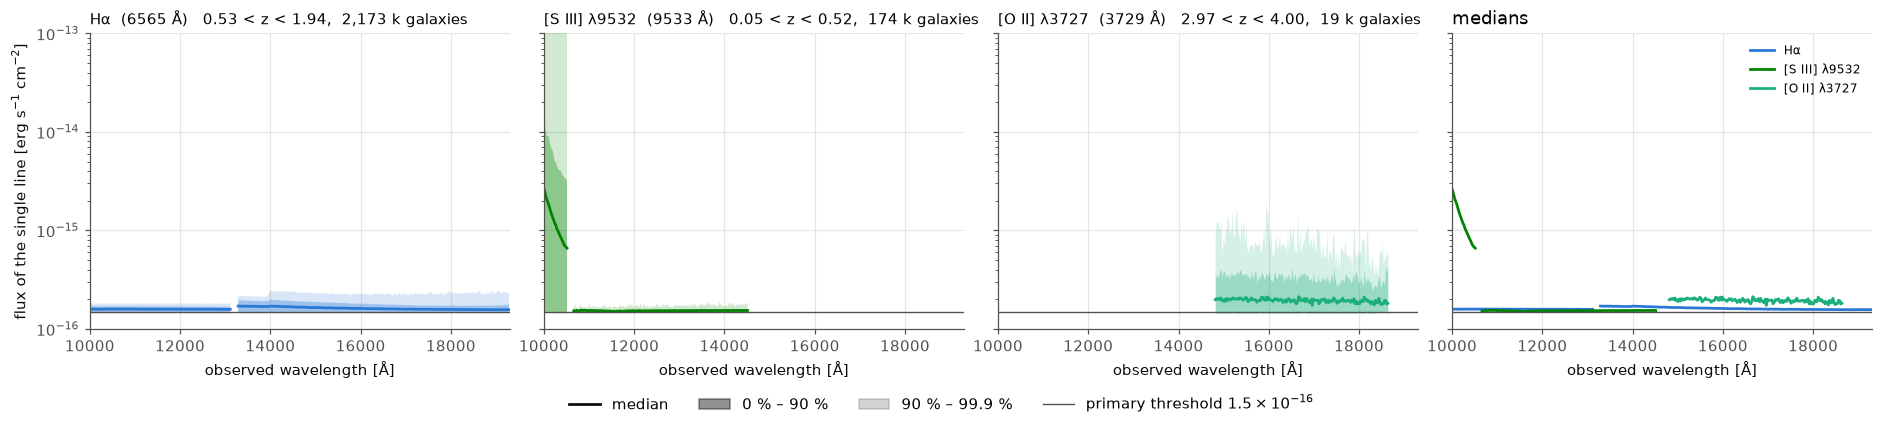

In [2]:
def quantile(h, q):
    '''Flux below which a fraction q of the galaxies of each wavelength bin lies (h: wavelength x flux histogram).
    Linear in log10 F inside a bin; q = 0 gives the lower edge of the first occupied bin.'''
    n = h.sum(axis=1)
    cum = np.concatenate([np.zeros((h.shape[0], 1)), np.cumsum(h, axis=1)], axis=1)        # at every flux edge
    out = np.full(n.size, np.nan)
    for j in np.flatnonzero(n):
        k = np.searchsorted(cum[j], q * n[j], side="right" if q == 0 else "left")        # first edge with cum >= target
        k = min(k, logf_edges.size - 1)
        lo, hi = cum[j][k - 1], cum[j][k]
        frac = (q * n[j] - lo) / (hi - lo) if hi > lo else 0.0
        out[j] = logf_edges[k - 1] + frac * (logf_edges[k] - logf_edges[k - 1])
    return 10.0 ** out

MIN_GAL = 20
n_panels = len(KEEP) + 1
ncols = min(n_panels, 4)
nrows = -(-n_panels // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.25 * ncols, 3.8 * nrows), sharex=True, sharey=True, constrained_layout=True, squeeze=False)
for ax, line in zip(axes.ravel(), KEEP):
    i, col = LINES.index(line), plotting.feature_color(line)
    ok = hist[i].sum(axis=1) >= MIN_GAL
    q = {p: np.where(ok, quantile(hist[i], p), np.nan) for p in (0.0, 0.5, 0.9, 0.999)}
    ax.fill_between(wave_c, q[0.9], q[0.999], color=col, alpha=0.18, lw=0)
    ax.fill_between(wave_c, q[0.0], q[0.9], color=col, alpha=0.45, lw=0)
    ax.plot(wave_c, q[0.5], color=col, lw=1.8)
    ax.axhline(F_PRIMARY, color=plotting.TEXT_SECONDARY, lw=0.9)
    z_lo, z_hi = wave_c[ok].min() / rest[i] - 1, wave_c[ok].max() / rest[i] - 1
    ax.set_title(f"{LABEL[line]}  ({rest[i]:.0f} Å)   {z_lo:.2f} < z < {z_hi:.2f},  {hist[i].sum() / 1e3:,.0f} k galaxies", loc="left", fontsize=9.5)
ax = axes.ravel()[len(KEEP)]
for line in KEEP:
    ok = hist[LINES.index(line)].sum(axis=1) >= MIN_GAL
    ax.plot(wave_c, np.where(ok, quantile(hist[LINES.index(line)], 0.5), np.nan), color=plotting.feature_color(line), lw=1.8, label=LABEL[line])
ax.axhline(F_PRIMARY, color=plotting.TEXT_SECONDARY, lw=0.9)
ax.set_title("medians", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper right")
for ax in axes.ravel()[n_panels:]:
    ax.set_visible(False)
for ax in axes.ravel()[:n_panels]:
    ax.set_yscale("log")
    ax.set_ylim(1e-16, 1e-13)
    ax.set_xlim(*WAVE_RANGE)
    ax.set_xlabel("observed wavelength [Å]")
for ax in axes[:, 0]:
    ax.set_ylabel("flux of the single line [erg s$^{-1}$ cm$^{-2}$]")
handles = [Line2D([], [], color=plotting.TEXT_PRIMARY, lw=1.8, label="median"),
           Patch(color=plotting.TEXT_PRIMARY, alpha=0.45, label="0 % – 90 %"),
           Patch(color=plotting.TEXT_PRIMARY, alpha=0.18, label="90 % – 99.9 %"),
           Line2D([], [], color=plotting.TEXT_SECONDARY, lw=0.9, label=f"primary threshold {sci(F_PRIMARY)}")]
fig.legend(handles=handles, loc="outside lower center", ncol=4, frameon=False)
plt.show()

## Which line is the single line, per slice of the bandpass

The bandpass is cut into twelve ranges of 775 Å. In each range the single-line galaxies whose line falls in the
range and is brighter than a flux threshold F are counted per kept line, and the shares are stacked: Hα on top,
reaching 100 %, then the other kept lines in order of brightness, the faintest at the bottom, so the height of
each band is the probability that a single line of flux above F at that wavelength is that line.
The vertical line is the primary threshold 1.5×10⁻¹⁶: below it every single-line galaxy of the range counts, so
the shares are constant; above it the sample shrinks to the brighter single lines. The stack is drawn where at
least 100 single-line galaxies exceed the threshold, which is why it ends before 10⁻¹².

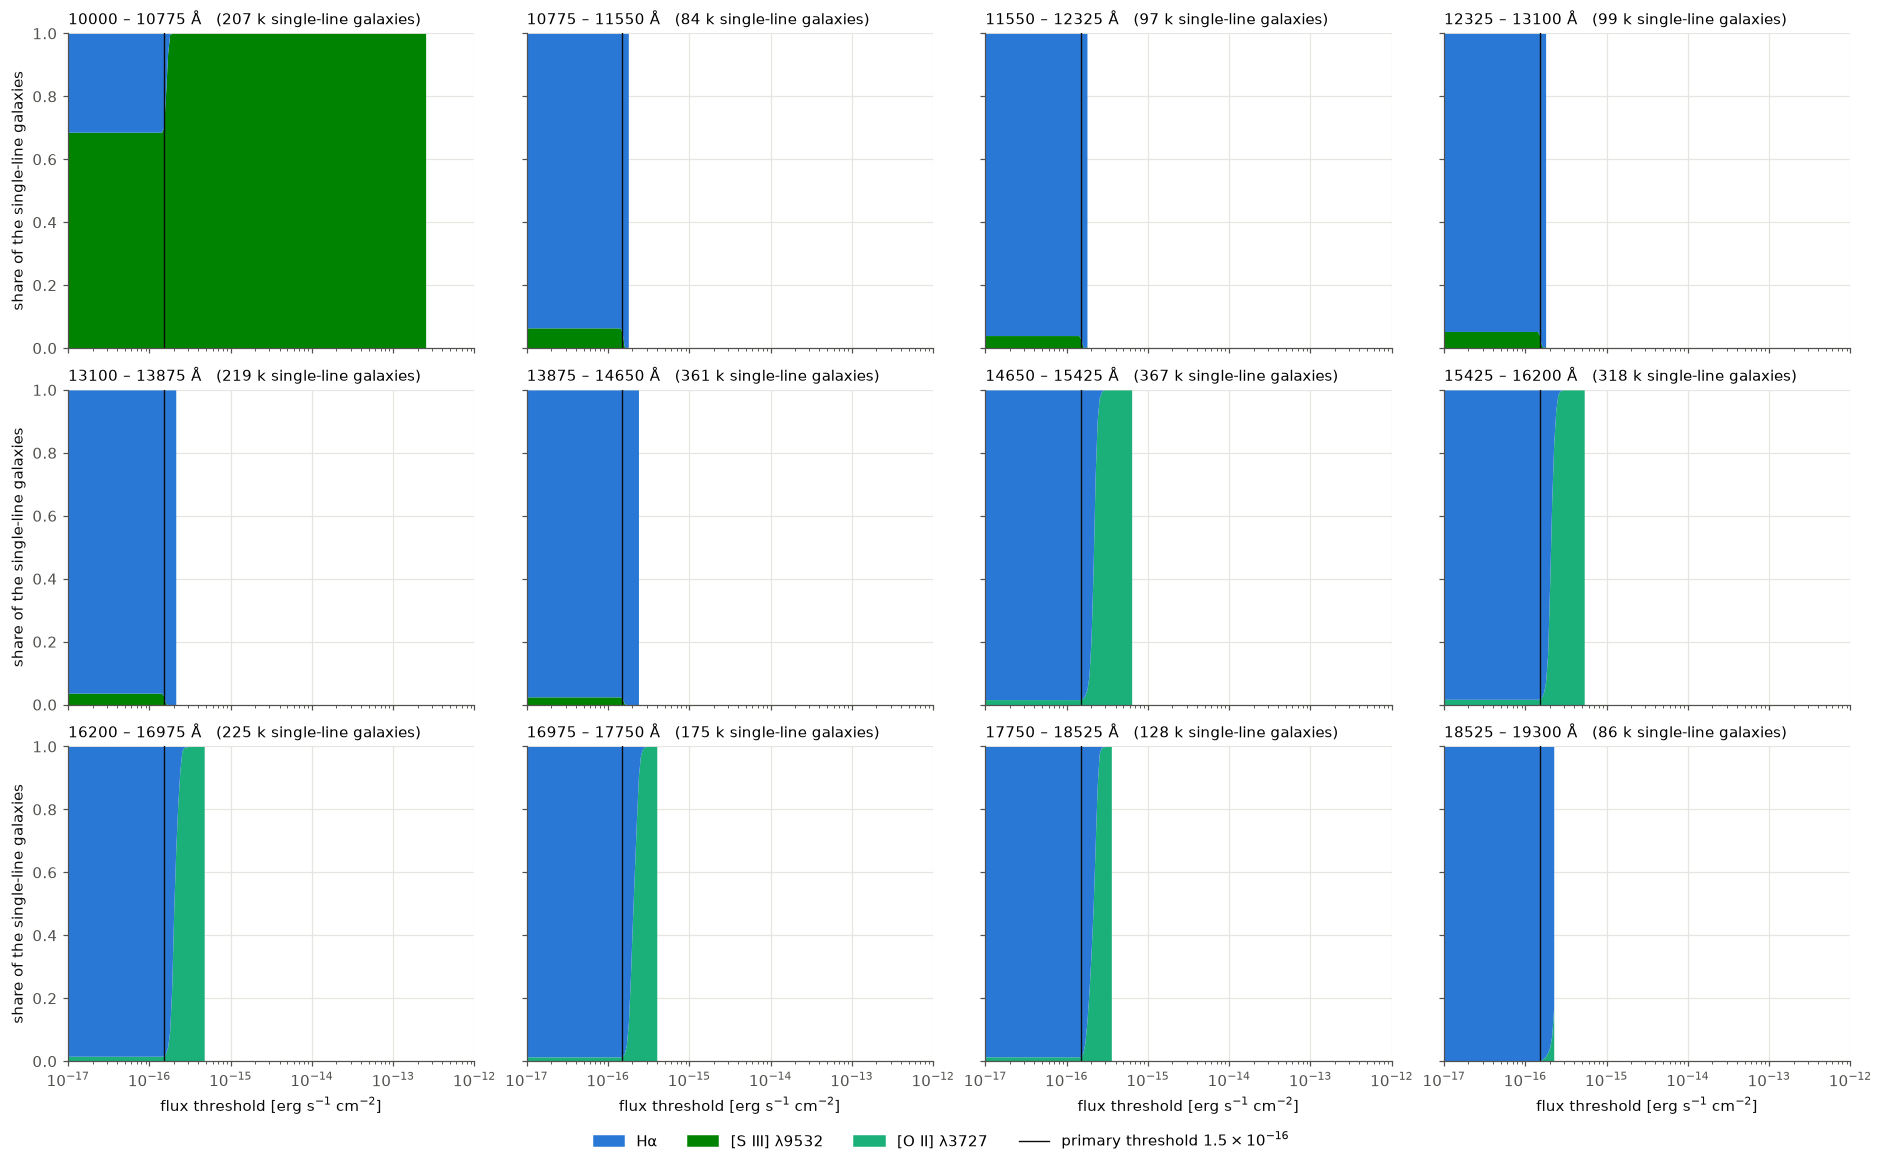


share of each line among the single-line galaxies brighter than 1.5e-16 erg/s/cm^2, per wavelength range
range [Å]                    Hα  [S III] λ9532   [O II] λ3727
 10000 – 10775            0.295          0.705          0.000
 10775 – 11550            0.953          0.047          0.000
 11550 – 12325            0.973          0.027          0.000
 12325 – 13100            0.960          0.040          0.000
 13100 – 13875            0.972          0.028          0.000
 13875 – 14650            0.981          0.019          0.000
 14650 – 15425            0.983          0.000          0.017
 15425 – 16200            0.982          0.000          0.018
 16200 – 16975            0.983          0.000          0.017
 16975 – 17750            0.985          0.000          0.015
 17750 – 18525            0.985          0.000          0.015
 18525 – 19300            0.998          0.000          0.002

share of each line among the single-line galaxies brighter than 1.0e-15 erg/s/cm^2, per

In [3]:
logf = np.linspace(-17, -12, 201)                                        # thresholds 1e-17 .. 1e-12
STACK = KEEP[::-1]                                                       # bottom to top: faintest line first, Hα on top

def number_above(h):
    '''Galaxies of a flux histogram brighter than each threshold of `logf` (linear inside a bin).'''
    cum = np.concatenate([np.cumsum(h[::-1])[::-1], [0]]).astype(np.float64)        # at every flux edge
    return np.interp(logf, logf_edges, cum, left=cum[0], right=cum[-1])

fig, axes = plt.subplots(3, 4, figsize=(17, 10.5), sharex=True, sharey=True, constrained_layout=True)
shares_at = {}
for ax, lo, hi in zip(axes.ravel(), edges[:-1], edges[1:]):
    sel = (wave_c >= lo) & (wave_c < hi)
    n = {line: number_above(hist[LINES.index(line)][sel].sum(axis=0)) for line in KEEP}
    total = sum(n.values())
    with np.errstate(invalid="ignore", divide="ignore"):
        share = {line: np.where(total >= 100, n[line] / total, np.nan) for line in KEEP}
    bottom = np.zeros_like(logf)
    for line in STACK:
        ax.fill_between(10.0 ** logf, bottom, bottom + share[line], color=plotting.feature_color(line), lw=0, label=LABEL[line])
        bottom = bottom + share[line]
    ax.axvline(F_PRIMARY, color=plotting.TEXT_PRIMARY, lw=0.9)
    ax.set_xscale("log")
    ax.set_xlim(1e-17, 1e-12)
    ax.set_ylim(0, 1)
    ax.set_title(f"{lo:.0f} – {hi:.0f} Å   ({total[0] / 1e3:,.0f} k single-line galaxies)", loc="left", fontsize=10)
    shares_at[(lo, hi)] = {F: {line: np.interp(np.log10(F), logf, share[line]) for line in KEEP} for F in (F_PRIMARY, 1e-15)}
for ax in axes[:, 0]:
    ax.set_ylabel("share of the single-line galaxies")
for ax in axes[-1]:
    ax.set_xlabel("flux threshold [erg s$^{-1}$ cm$^{-2}$]")
handles = [Patch(color=plotting.feature_color(line), label=LABEL[line]) for line in KEEP]
handles.append(Line2D([], [], color=plotting.TEXT_PRIMARY, lw=0.9, label=f"primary threshold {sci(F_PRIMARY)}"))
fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), frameon=False)
plt.show()

for F in (F_PRIMARY, 1e-15):
    print(f"\nshare of each line among the single-line galaxies brighter than {F:.1e} erg/s/cm^2, per wavelength range")
    print(f"{'range [Å]':<16s}" + "".join(f"{LABEL[l]:>15s}" for l in KEEP))
    for (lo, hi), s in shares_at.items():
        print(f"{lo:6.0f} – {hi:5.0f}  " + "".join(f"{s[F][l]:15.3f}" if np.isfinite(s[F][l]) else f"{'—':>15s}" for l in KEEP))

## What the plots show

**Single-line galaxies are faint Hα emitters, plus two corners of the bandpass.** With no second line above
6×10⁻¹⁷ allowed, 92 % of the single-line galaxies are Hα, 7 % [S III] λ9532 and 0.8 % [O II] (1.5–1.8 % of the
single lines at 14 650–18 525 Å, which is why it is kept). [O III] λ5007, Hβ, [O III] λ4959 and [S III] λ9069 are
(almost) never the single line — 22, 3, 0 and 0 galaxies — and are dropped from the plots. The reason is the line
model of the mock,
whose ratios are nearly fixed (notebook 04): Hβ/[O III] λ5007 = 0.45 and [O III] λ4959/λ5007 = 0.329, so an
[O III] λ5007 line above 1.5×10⁻¹⁶ always comes with Hβ above 6.7×10⁻¹⁷ while both are in the bandpass
(1.06 < z < 2.84), and above 1.8×10⁻¹⁶ with λ4959 too. An Hα emitter is single-line only when its
[O III] λ5007 (0.3–0.7 of Hα, median 0.44) and its [S III] lines (λ9532 at 0.35–0.8 of Hα) stay below 6×10⁻¹⁷,
which confines the single Hα lines to 1.5–4×10⁻¹⁶: the narrow bands of the first figure, and the end of every
stack a factor of 2–3 above the primary threshold in the second. The dip of Hα at 13 000–14 000 Å
(1.0 < z < 1.13) is where [O III] λ5007 has entered the bandpass while [S III] λ9069 has not yet left it.

**The two corners.** At 10 000–10 500 Å (0.05 < z < 0.10) [S III] λ9532 is the only line of the seven inside the
bandpass, so every [S III] λ9532 emitter there is single-line whatever its flux: the bright tail up to 10⁻¹³ in
the first figure and the only stack that extends beyond 10⁻¹⁵. Above 14 800 Å (z > 2.97) Hβ has left the
bandpass and [O II] is alone, so the [O II] emitters there are single-line; they are faint, 1.5–3×10⁻¹⁶.

**For line identification.** At the primary threshold a single line is Hα with a probability of 95–99 % at
every wavelength above 10 775 Å; the one exception is the bluest range, 10 000–10 775 Å, where 70 % of the single
lines are [S III] λ9532 from z < 0.13. The table above gives the shares per range.